# 02 · Fine-tuning Faster R-CNN for Pedestrian Detection

Training a detector from scratch needs far more data and compute than we have, so (as the slides recommend) we use **transfer learning**:

1. Start from torchvision's Faster R-CNN (ResNet-50 + FPN, v2), pretrained on COCO
2. Replace its 91-class head with a 2-class head: background and pedestrian
3. **Freeze the backbone** and fine-tune only the region proposal network and the detection heads on MOT16 (few-shot fine-tuning)

We measure the detector **before and after** fine-tuning on MOT16-09, which it never sees during training.

Runtime: **T4 GPU**, about 45–60 minutes. If Colab disconnects, just run everything again: training resumes from the last finished epoch.

In [1]:
# ---- Setup (identical in every notebook) -----------------------------------
# The ONLY line you may need to change: where the project folder sits on your Drive.
# If a teammate shared the folder with you, right-click it in Drive ->
# "Organize" -> "Add shortcut" -> My Drive, and this path will work unchanged.
PROJECT_DIR = "/content/drive/MyDrive/DL_Project_MOT"

from google.colab import drive
drive.mount("/content/drive")

import os, sys
assert os.path.isdir(os.path.join(PROJECT_DIR, "src")), (
    f"Can't find {PROJECT_DIR}/src. Upload the project folder to Drive first (see README).")
sys.path.insert(0, os.path.join(PROJECT_DIR, "src"))

import config
paths = config.get_paths(PROJECT_DIR)

import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU (switch the runtime to T4 GPU!)")

Mounted at /content/drive
Device: Tesla T4


In [2]:
import gc, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mot_data import prepare_mot16, parse_gt, parse_ignore_regions, MOT16DetectionDataset, collate_fn
from detector import (build_coco_detector, build_pedestrian_detector, load_pedestrian_detector,
                      count_params, train_detector, detect_sequence, evaluate_detections)

MOT_ROOT = prepare_mot16(paths)
val_dir = f"{MOT_ROOT}/train/{config.VAL_SEQ}"
val_gt, val_ignore = parse_gt(val_dir), parse_ignore_regions(val_dir)

Unzipping MOT16.zip to /content/MOT16 ...
MOT16 ready at /content/MOT16


## 1. Baseline: the COCO detector without any fine-tuning

COCO already has a "person" class, so the pretrained model can detect pedestrians out of the box.
This is our "before" number. We evaluate on every 3rd frame of MOT16-09 to save time.

**Metric:** Average Precision at IoU 0.5 (AP@0.5): the area under the precision-recall curve, i.e. how well the detector ranks real people above false alarms. We also report precision and recall at a 0.5 confidence threshold.

In [3]:
EVAL_STEP = 3   # every 3rd validation frame

coco = build_coco_detector().to(device).eval()
coco_dets, coco_fps = detect_sequence(coco, val_dir, device, score_thresh=0.05, frame_step=EVAL_STEP)
coco_res = evaluate_detections(coco_dets, val_gt, val_ignore)
print(f"COCO pretrained  ->  AP@0.5 {coco_res['AP']:.3f} | precision {coco_res['precision']:.3f} "
      f"| recall {coco_res['recall']:.3f} | {coco_fps:.1f} FPS")

del coco; gc.collect(); torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:01<00:00, 158MB/s]


  MOT16-09: 100/175 frames
COCO pretrained  ->  AP@0.5 0.741 | precision 0.664 | recall 0.751 | 7.4 FPS


## 2. Training data

* Six training videos (everything except MOT16-09)
* Every 2nd frame: neighbouring frames are almost identical, so this halves training time at almost no cost
* Augmentation on (flip, colour jitter, blur), see notebook 01

**Why split by video and not by random frames?** If frame 100 is in training and frame 101 in validation, the model has basically already seen the validation image. Splitting by whole videos avoids this leakage.

In [4]:
train_ds = MOT16DetectionDataset(MOT_ROOT, config.TRAIN_SEQS, frame_step=2, train=True)
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=4, shuffle=True, num_workers=2,
                                           collate_fn=collate_fn, pin_memory=True)
print(f"{len(train_ds)} training frames -> {len(train_loader)} batches per epoch")

2396 training frames -> 599 batches per epoch


In [5]:
model = build_pedestrian_detector(freeze_backbone=True).to(device)
trainable, frozen = count_params(model)
print(f"Trainable parameters: {trainable / 1e6:.1f} M  |  frozen (backbone): {frozen / 1e6:.1f} M")

Trainable parameters: 16.4 M  |  frozen (backbone): 26.9 M


## 3. Fine-tune

* SGD, lr 0.005, momentum 0.9, weight decay 5e-4
* Linear warm-up for 300 steps, then cosine decay
* Mixed precision (fp16) to fit 4 images per batch on a T4
* After every epoch: quick validation AP on every 10th frame of MOT16-09, plus a checkpoint on Drive

If you get a CUDA out-of-memory error, change `batch_size=4` to `2` in the cell above.

In [6]:
EPOCHS = 4

def quick_val(m):
    dets, _ = detect_sequence(m, val_dir, device, score_thresh=0.05, frame_step=10, verbose=False)
    m.train()
    return evaluate_detections(dets, val_gt, val_ignore)["AP"]

history = train_detector(model, train_loader, device, epochs=EPOCHS, ckpt_path=paths.detector_ckpt,
                         lr=0.005, val_fn=quick_val)

  epoch 1 | step 50/599 | loss 1.3870 | lr 0.00085
  epoch 1 | step 100/599 | loss 1.1455 | lr 0.00168
  epoch 1 | step 150/599 | loss 0.9915 | lr 0.00252
  epoch 1 | step 200/599 | loss 0.9091 | lr 0.00335
  epoch 1 | step 250/599 | loss 0.8431 | lr 0.00418
  epoch 1 | step 300/599 | loss 0.7968 | lr 0.00500
  epoch 1 | step 350/599 | loss 0.7605 | lr 0.00499
  epoch 1 | step 400/599 | loss 0.7331 | lr 0.00497
  epoch 1 | step 450/599 | loss 0.7115 | lr 0.00494
  epoch 1 | step 500/599 | loss 0.6929 | lr 0.00489
  epoch 1 | step 550/599 | loss 0.6778 | lr 0.00483
Epoch 1: train loss 0.6644 (6.9 min) | val AP@0.5 0.800
  epoch 2 | step 50/599 | loss 0.5196 | lr 0.00467
  epoch 2 | step 100/599 | loss 0.5072 | lr 0.00457
  epoch 2 | step 150/599 | loss 0.5056 | lr 0.00445
  epoch 2 | step 200/599 | loss 0.4974 | lr 0.00433
  epoch 2 | step 250/599 | loss 0.4949 | lr 0.00420
  epoch 2 | step 300/599 | loss 0.4933 | lr 0.00406
  epoch 2 | step 350/599 | loss 0.4920 | lr 0.00391
  epoch 2 

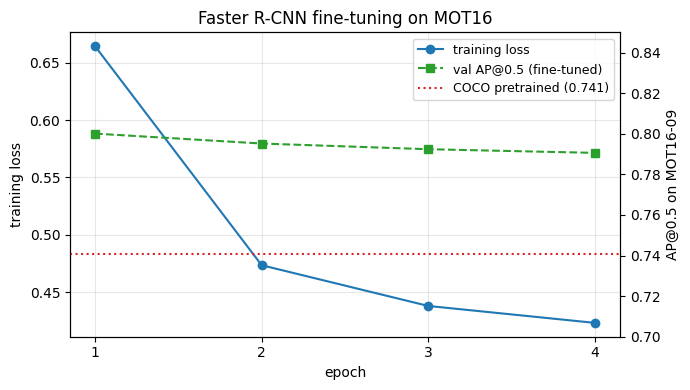

In [8]:
fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(history["epoch"], history["train_loss"], "o-", color="tab:blue", label="training loss")
ax1.set_xlabel("epoch"); ax1.set_ylabel("training loss"); ax1.set_xticks(history["epoch"]); ax1.grid(alpha=.3)

ax2 = ax1.twinx()
ax2.plot(history["epoch"], history["val_ap"], "s--", color="tab:green", label="val AP@0.5 (fine-tuned)")
ax2.axhline(coco_res["AP"], color="tab:red", ls=":", label=f"COCO pretrained ({coco_res['AP']:.3f})")
ax2.set_ylim(0.70, 0.85); ax2.set_ylabel("AP@0.5 on MOT16-09")

h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=9)
plt.title("Faster R-CNN fine-tuning on MOT16")
plt.tight_layout(); plt.savefig(f"{paths.figures}/detector_training.png", dpi=150); plt.show()

## 4. Before vs after fine-tuning

In [9]:
model = load_pedestrian_detector(paths.detector_ckpt, device)
ft_dets, ft_fps = detect_sequence(model, val_dir, device, score_thresh=0.05, frame_step=EVAL_STEP)
ft_res = evaluate_detections(ft_dets, val_gt, val_ignore)

table = pd.DataFrame([
    {"Detector": "Faster R-CNN, COCO pretrained", "AP@0.5": coco_res["AP"],
     "Precision@0.5": coco_res["precision"], "Recall@0.5": coco_res["recall"], "FPS": round(coco_fps, 1)},
    {"Detector": "Faster R-CNN, fine-tuned on MOT16 (ours)", "AP@0.5": ft_res["AP"],
     "Precision@0.5": ft_res["precision"], "Recall@0.5": ft_res["recall"], "FPS": round(ft_fps, 1)},
])
table.to_csv(f"{paths.tables}/detector_results.csv", index=False)
table

  MOT16-09: 100/175 frames


,Detector,AP@0.5,Precision@0.5,Recall@0.5,FPS
0,"Faster R-CNN, COCO pretrained",0.7410,0.6638,0.7510,7.4
1,"Faster R-CNN, fine-tuned on MOT16 (ours)",0.7799,0.7428,0.7687,9.6


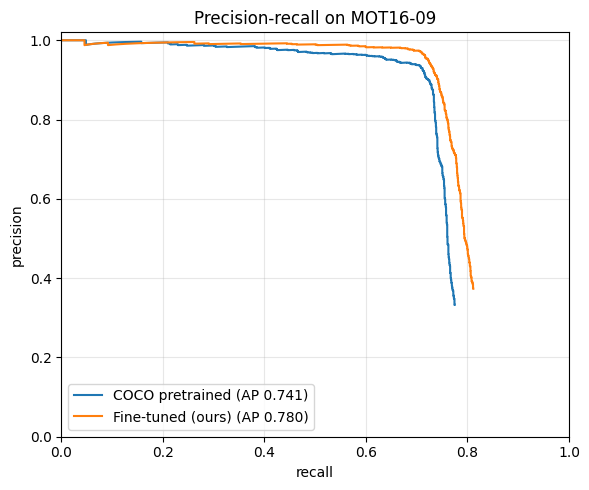

In [10]:
plt.figure(figsize=(6, 5))
for name, res in [("COCO pretrained", coco_res), ("Fine-tuned (ours)", ft_res)]:
    r, p = res["curve"]
    plt.plot(r, p, label=f"{name} (AP {res['AP']:.3f})")
plt.xlabel("recall"); plt.ylabel("precision"); plt.xlim(0, 1); plt.ylim(0, 1.02)
plt.title(f"Precision-recall on {config.VAL_SEQ}"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{paths.figures}/detector_pr_curve.png", dpi=150); plt.show()

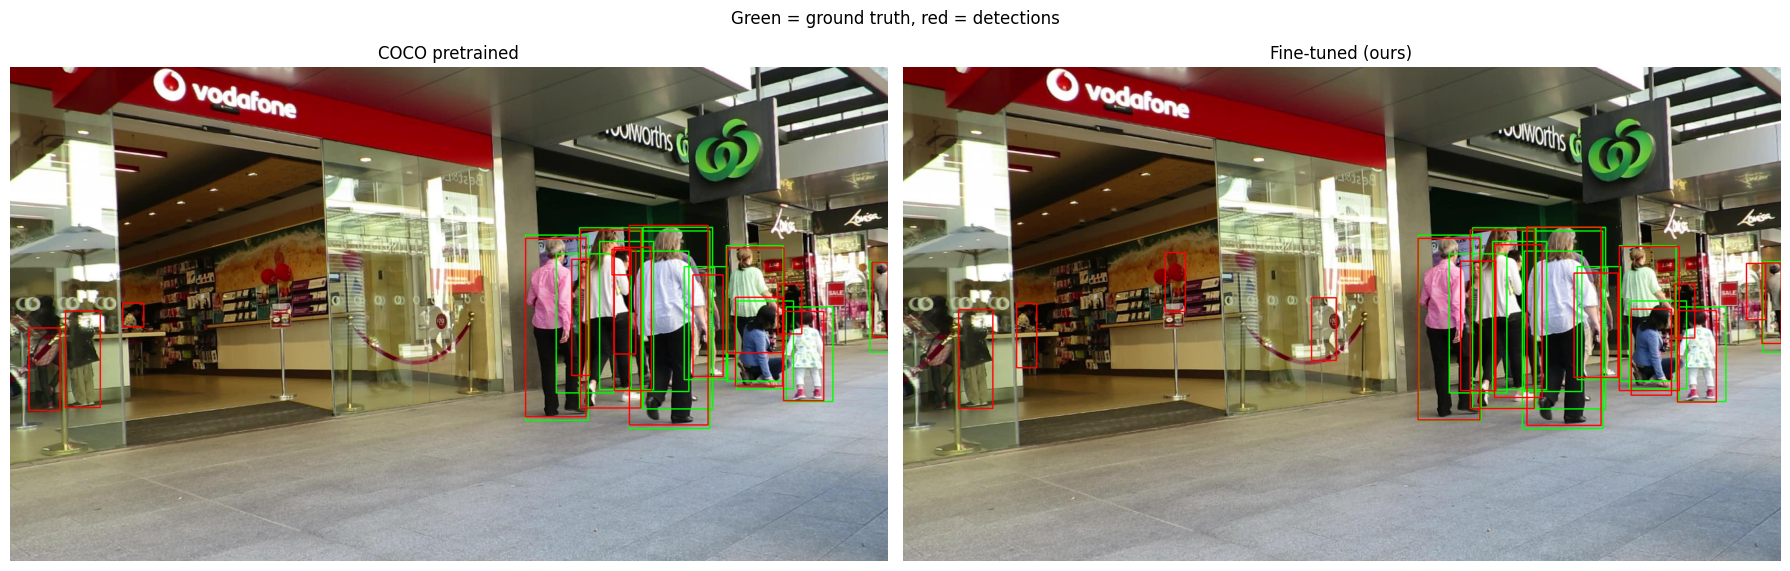

In [11]:
# Side-by-side on one validation frame: green = ground truth, red = detections (score >= 0.5)
import cv2
from mot_data import read_seqinfo, frame_path
info = read_seqinfo(val_dir)
f = 300   # any frame works; pick a crowded one

coco = build_coco_detector().to(device).eval()
from detector import detect
img = cv2.imread(frame_path(val_dir, info, f))
panels = []
for name, m in [("COCO pretrained", coco), ("Fine-tuned (ours)", model)]:
    vis = img.copy()
    for _, x1, y1, x2, y2 in val_gt.get(f, []):
        cv2.rectangle(vis, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
    for x1, y1, x2, y2, s in detect(m, img, device, 0.5):
        cv2.rectangle(vis, (int(x1), int(y1)), (int(x2), int(y2)), (0, 0, 255), 2)
    panels.append((name, vis))
del coco; torch.cuda.empty_cache()

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, (name, vis) in zip(axes, panels):
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax.set_title(name); ax.axis("off")
plt.suptitle("Green = ground truth, red = detections")
plt.tight_layout(); plt.savefig(f"{paths.figures}/detector_qualitative.jpg", dpi=110); plt.show()

## Done ✅

* Model: `weights/detector_frcnn_mot16.pth` (stays on Drive, **never** goes to GitHub or Canvas)
* Table: `results/tables/detector_results.csv`
* Figures: `detector_training.png`, `detector_pr_curve.png`, `detector_qualitative.jpg`

**For the report:** compare the two rows above. Fine-tuning normally raises AP and recall, because MOT16 pedestrians are smaller, more crowded and more occluded than typical COCO people. Whatever the numbers turn out to be, report them as they are and explain them; that is what the "self-evaluation" section is for.